# Retinal Image Modality Classification: FAF / IR / OTHER

This notebook compares image-only CNN models for classifying retinal images into `FAF`, `IR`, and `OTHER`.

**Models compared:** ResNet-18, DenseNet-121, and EfficientNet-B0. ResNet-18 is a useful lightweight baseline; the other architectures are compared using the same cross-validation folds.

**Initialisation compared:** every model is trained twice, with ImageNet-pretrained weights (`pretrained=True`) and with random weights from scratch (`pretrained=False`). The best model of each kind is evaluated on the held-out test set.

**Circle mask (`USE_CIRCLE_MASK`).** Some images are round (black corners) and others square, and the round shape was acting as a shortcut for FAF (Grad-CAM showed the model looking at the black corners). Every image, in every class, for training, validation, test and prediction, is therefore masked to the same centred circle, so the outline can no longer reveal the class and the model has to use the retina.

**No metadata is used as a model input.** The CSV is used only to read image paths and ground-truth labels. Optional patient/subject IDs may be used only to keep patients separated across cross-validation folds.

**Expected CSV columns**
- `image_path`: path to an image file
- `label`: one of `FAF`, `IR`, `OTHER`
- Optional `patient_id` or `subject_id`: only for group-aware splitting, not as a feature

Run cells from top to bottom. Edit the configuration cell first. The notebook selects a model using cross-validation, then evaluates the selected model on the held-out test set once.

## 1. Install dependencies
Run once if needed. If using a managed environment, install packages in your terminal instead.

In [1]:
# Uncomment if needed:
# %pip install torch torchvision scikit-learn pandas pillow matplotlib

## 2. Imports and reproducibility

In [2]:
import os
import copy
import json
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import StratifiedKFold
try:
    from sklearn.model_selection import StratifiedGroupKFold
    HAS_GROUP_SPLIT = True
except ImportError:
    HAS_GROUP_SPLIT = False

from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print("Device:", DEVICE)

Device: cuda


## 3. Configuration

Update the CSV paths below. Each CSV should contain `image_path` and `label` columns. Paths should point to image files accessible from this notebook.

`PRETRAINED_MODES = [True, False]` runs every model twice:
- **True**: ImageNet weights, fine-tuned on your images (transfer learning). Good for small datasets. The first run downloads weights.
- **False**: random weights (`weights=None`); the whole network is trained from scratch. It needs more epochs and a higher learning rate, so it has its own settings.

Use `[True]` or `[False]` to run only one of them.

`USE_CIRCLE_MASK = True` blacks out everything outside the centred circle on **every** image (all classes, train and test). `CIRCLE_SCALE` below 1.0 (e.g. 0.95) also trims the circle's edge, in case the edge itself differs between devices.

The default comparison includes three CNNs: ResNet-18, DenseNet-121 and EfficientNet-B0. ResNet-50 can be added to `MODEL_NAMES` if needed.

In [3]:
TRAIN_CSV = "train_labels.csv"
TEST_CSV = "test_labels.csv"
OUTPUT_DIR = "results_faf_ir_model_comparison"

IMAGE_SIZE = 330
BATCH_SIZE = 8
NUM_WORKERS = 0
N_FOLDS = 5
SEED = 42

# Models to compare. Supported: resnet18, resnet50, resnet101, densenet121, efficientnet_b0
# MODEL_NAMES = ["resnet18", "densenet121", "efficientnet_b0"]

MODEL_NAMES = ["resnet18", "resnet50", "resnet101", "densenet121", "efficientnet_b0"]
# Run every model with ImageNet weights (True) AND from random weights (False)
# PRETRAINED_MODES = [True, False]
PRETRAINED_MODES = [True]

# Pretrained models (fine-tuning)
EPOCHS = 15
LEARNING_RATE = 1e-4
PATIENCE = 4

# Models trained from scratch: no prior knowledge, so longer training and a higher learning rate
SCRATCH_EPOCHS = 60
SCRATCH_LEARNING_RATE = 1e-3
SCRATCH_PATIENCE = 10

WEIGHT_DECAY = 1e-4

# Same round field of view for every image, so a round outline / black corners cannot reveal the class
USE_CIRCLE_MASK = True
CIRCLE_SCALE = 1.0   # 1.0 = largest circle that fits; 0.95 also trims the edge

def train_settings(pretrained):
    """Return (max epochs, learning rate, early-stopping patience) for this initialisation."""
    if pretrained:
        return EPOCHS, LEARNING_RATE, PATIENCE
    return SCRATCH_EPOCHS, SCRATCH_LEARNING_RATE, SCRATCH_PATIENCE

def init_name(pretrained):
    return "pretrained" if pretrained else "scratch"

# Imbalance handling: class-weighted cross-entropy loss (the only method used).

CLASSES = ["FAF", "IR", "OTHER"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}

os.makedirs(OUTPUT_DIR, exist_ok=True)
SUPPORTED_MODELS = {"resnet18", "resnet50", "resnet101", "densenet121", "efficientnet_b0"}
if not MODEL_NAMES or not set(MODEL_NAMES).issubset(SUPPORTED_MODELS):
    raise ValueError(f"MODEL_NAMES must be selected from: {sorted(SUPPORTED_MODELS)}")
if not PRETRAINED_MODES or not set(PRETRAINED_MODES).issubset({True, False}):
    raise ValueError("PRETRAINED_MODES must contain True and/or False.")
if len(set(MODEL_NAMES)) != len(MODEL_NAMES):
    raise ValueError("MODEL_NAMES contains duplicates.")

### Imbalance handling
This notebook uses **class-weighted cross-entropy loss only**. Class weights are calculated from each training fold (and from the full training set for final training), so underrepresented classes contribute more to the loss. No oversampling or image duplication is used, and validation/test data are left unchanged.

## 4. Load and validate CSV files
This cell checks required columns, class labels, image paths, and train/test path overlap. If your paths need changing, fix them in the CSV or edit the paths before continuing.

In [4]:
def load_labels(csv_path, expected_classes=CLASSES):
    df = pd.read_csv(csv_path)
    required = {"image_path", "label"}
    missing_cols = required - set(df.columns)
    if missing_cols:
        raise ValueError(f"{csv_path} is missing columns: {sorted(missing_cols)}")

    df = df.copy()
    df["image_path"] = df["image_path"].astype(str).str.strip()
    df["label"] = df["label"].astype(str).str.strip().str.upper()
    if df.empty:
        raise ValueError(f"{csv_path} contains no rows.")

    bad_labels = sorted(set(df["label"]) - set(expected_classes))
    if bad_labels:
        raise ValueError(f"Unexpected labels in {csv_path}: {bad_labels}. "
                         f"Expected only {expected_classes}")

    missing = [p for p in df["image_path"] if not os.path.isfile(p)]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} image paths do not exist in {csv_path}. "
            f"Example: {missing[0]}"
        )
    return df.reset_index(drop=True)

train_df = load_labels(TRAIN_CSV)
test_df = load_labels(TEST_CSV)

print("Training class counts:")
print(train_df["label"].value_counts().reindex(CLASSES, fill_value=0))
print("\nTest class counts:")
print(test_df["label"].value_counts().reindex(CLASSES, fill_value=0))

if set(train_df["label"]) != set(CLASSES):
    raise ValueError(f"Training CSV must contain all classes: {CLASSES}")

train_paths = set(os.path.normcase(os.path.abspath(p)) for p in train_df.image_path)
test_paths = set(os.path.normcase(os.path.abspath(p)) for p in test_df.image_path)
overlap = train_paths & test_paths
if overlap:
    raise ValueError(f"Train/test path leakage: {len(overlap)} identical paths. "
                     f"Remove overlap before training.")

# No patient ID column is used: cross-validation is image-level.
GROUP_COL = None

Training class counts:
label
FAF      87
IR       84
OTHER    82
Name: count, dtype: int64

Test class counts:
label
FAF      22
IR       13
OTHER    20
Name: count, dtype: int64


## 5. Image preprocessing and dataset
Images are resized while preserving aspect ratio and padded to a square. Then, if `USE_CIRCLE_MASK` is on, everything outside the centred circle is set to black, for **every** image (training, validation, test, prediction). Horizontal flips and mild rotations are used for training only.

The mask is applied in memory when an image is loaded; the image files are not changed.

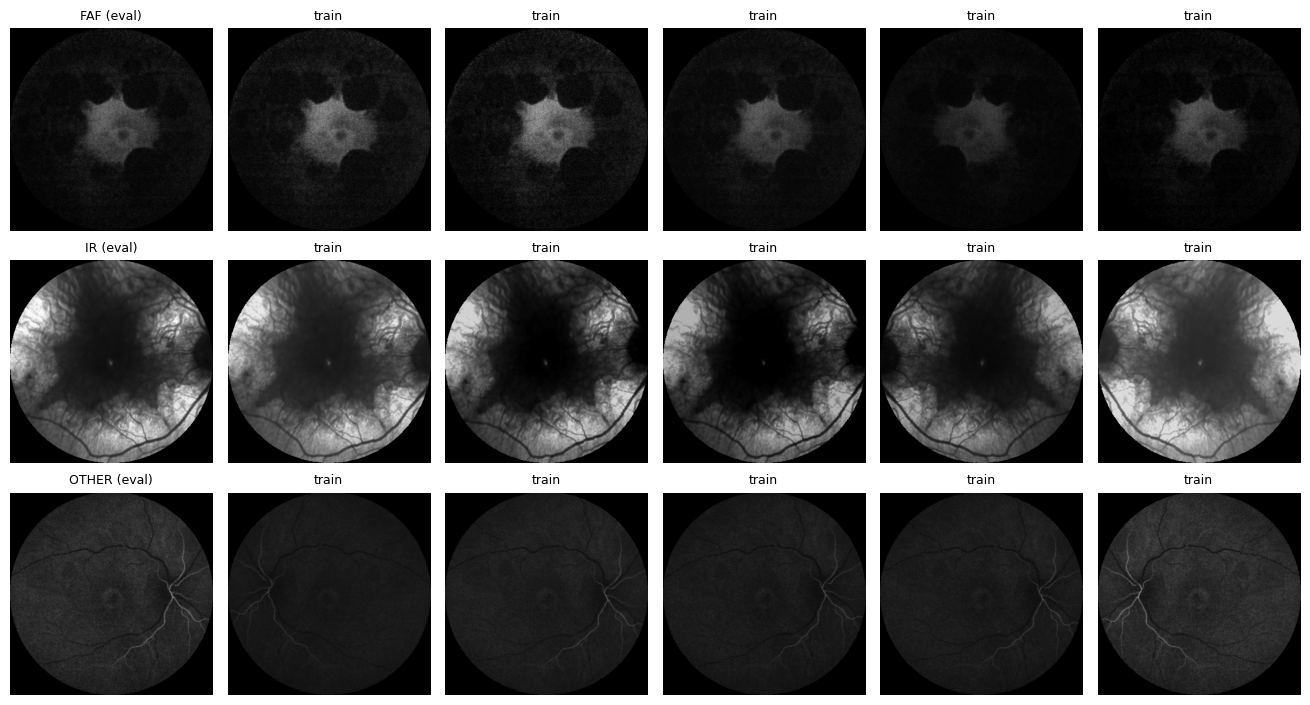

In [5]:
class ResizePad:
    def __init__(self, size, fill=0):
        self.size = int(size)
        self.fill = fill

    def __call__(self, image):
        image = ImageOps.exif_transpose(image).convert("RGB")
        # scale so the longer side equals `size` (up or down)
        scale = self.size / max(image.width, image.height)
        new_size = (max(1, round(image.width * scale)), max(1, round(image.height * scale)))
        image = image.resize(new_size, Image.Resampling.BILINEAR)
        canvas = Image.new("RGB", (self.size, self.size), (self.fill,) * 3)
        canvas.paste(image, ((self.size - image.width) // 2, (self.size - image.height) // 2))
        return canvas

class CircleMask:
    """Black out everything outside the centred circle (same for every class, train and test)."""
    def __init__(self, scale=1.0):
        self.scale = float(scale)

    def __call__(self, image):
        a = np.array(image)
        h, w = a.shape[:2]
        yy, xx = np.ogrid[:h, :w]
        r = min(h, w) / 2 * self.scale
        a[(yy - (h - 1) / 2) ** 2 + (xx - (w - 1) / 2) ** 2 > r ** 2] = 0
        return Image.fromarray(a)

def preprocess(size=IMAGE_SIZE, circle_mask=USE_CIRCLE_MASK, circle_scale=CIRCLE_SCALE):
    """Evaluation and display: resize + pad (+ circle mask). No brightness changes:
    brightness, vessels and lesions are real features."""
    steps = [ResizePad(size)]
    if circle_mask:
        steps.append(CircleMask(circle_scale))
    return transforms.Compose(steps)

def make_transforms(size=IMAGE_SIZE, circle_mask=USE_CIRCLE_MASK, circle_scale=CIRCLE_SCALE):
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    mask_img = [CircleMask(circle_scale)] if circle_mask else []

    train_tf = transforms.Compose([            # geometric + brightness/contrast jitter (vessels, lesions untouched)
        ResizePad(size),
        transforms.ColorJitter(brightness=0.4, contrast=0.4),   # bright/high-contrast and dim/faint FAF; before the mask so the corners stay black
        *mask_img,
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=7),
        *mask_img,                             # keep the circle identical after rotation
        transforms.ToTensor(),
        normalize,
    ])
    eval_tf = transforms.Compose([             # validation, test, prediction: no randomness
        preprocess(size, circle_mask, circle_scale),
        transforms.ToTensor(),
        normalize,
    ])
    return train_tf, eval_tf

class RetinalImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["image_path"]) as im:
            image = im.convert("RGB")
        return self.transform(image), CLASS_TO_IDX[row["label"]]

train_transform, eval_transform = make_transforms()

# Check what training sees: one image per class, original + 5 random training versions
def show_augmentations(n_aug=5):
    mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    examples = train_df.groupby("label").head(1)
    fig, axes = plt.subplots(len(examples), n_aug + 1, figsize=(2.2 * (n_aug + 1), 2.4 * len(examples)), squeeze=False)
    for r, (_, row) in enumerate(examples.iterrows()):
        with Image.open(row["image_path"]) as im:
            original = im.convert("RGB")
        axes[r, 0].imshow(preprocess()(original)); axes[r, 0].set_title(f"{row['label']} (eval)", fontsize=9)
        for c in range(1, n_aug + 1):
            t = train_transform(original).permute(1, 2, 0).numpy() * std + mean
            axes[r, c].imshow(t.clip(0, 1)); axes[r, c].set_title("train", fontsize=9)
        for ax in axes[r]:
            ax.axis("off")
    plt.tight_layout(); plt.show()

show_augmentations()

## 6. Model, loss, and data loaders
Class weights are computed from each training fold only. Oversampling is an alternative to class-weighted loss; do not combine them in the same experiment.

In [6]:
def build_model(model_name, pretrained=True, n_classes=len(CLASSES)):
    # pretrained=True  -> ImageNet weights
    # pretrained=False -> weights=None (random weights, trained from scratch)
    if model_name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, n_classes)
    elif model_name == "resnet50":
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        model = models.resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, n_classes)
    elif model_name == "resnet101":
        weights = models.ResNet101_Weights.DEFAULT if pretrained else None
        model = models.resnet101(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, n_classes)
    elif model_name == "densenet121":
        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        model = models.densenet121(weights=weights)
        model.classifier = nn.Linear(model.classifier.in_features, n_classes)
    elif model_name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, n_classes)
    else:
        raise ValueError(f"Unsupported model: {model_name}")
    return model

def make_loader(df, transform, train=False):
    # Keep the natural class distribution in each split; no oversampling.
    ds = RetinalImageDataset(df, transform)
    return DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=train,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )

def make_loss(df):
    # Calculate inverse-frequency class weights using this training partition only.
    y = np.array([CLASS_TO_IDX[x] for x in df["label"]])
    counts = np.bincount(y, minlength=len(CLASSES)).astype(float)
    if np.any(counts == 0):
        raise ValueError("A training fold is missing a class.")
    weights = len(y) / (len(CLASSES) * counts)
    weight_tensor = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
    print("Class weights:", dict(zip(CLASSES, np.round(weights, 3))))
    return nn.CrossEntropyLoss(weight=weight_tensor)

## 7. Training and evaluation helpers

In [7]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            y_true.extend(labels.detach().cpu().numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())

    return total_loss / max(1, len(y_true)), np.asarray(y_true), np.asarray(y_pred)

def score_predictions(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "report": classification_report(
            y_true, y_pred, labels=list(range(len(CLASSES))),
            target_names=CLASSES, digits=3, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=list(range(len(CLASSES)))
        )
    }

def train_with_early_stopping(model, train_loader, val_loader, criterion,
                              epochs, lr, patience):
    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=lr, weight_decay=WEIGHT_DECAY
    )
    best_state = copy.deepcopy(model.state_dict())
    best_f1, best_epoch, wait = -1.0, 0, 0
    history = []

    for epoch in range(1, epochs + 1):
        tr_loss, y_tr, p_tr = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, y_val, p_val = run_epoch(model, val_loader, criterion)
        val_f1 = f1_score(y_val, p_val, average="macro", zero_division=0)
        tr_acc = accuracy_score(y_tr, p_tr)
        val_acc = accuracy_score(y_val, p_val)
        history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": val_loss,
                        "train_acc": tr_acc, "val_acc": val_acc, "val_macro_f1": val_f1})
        print(f"Epoch {epoch:02d}/{epochs} | train loss={tr_loss:.4f} | val loss={val_loss:.4f} "
              f"| train acc={tr_acc:.4f} | val acc={val_acc:.4f} | val macro-F1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_state)
    return model, history, best_epoch

def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    plt.show()

## 8. Compare models with cross-validation (pretrained and from scratch)

Every model is trained with both initialisations on the **same folds**, with the same preprocessing and class-weighted loss. Within each initialisation, the model with the highest mean validation macro-F1 is selected. The held-out test set is not used to choose models.

In [8]:
def get_cv_splits(df):
    y = np.array([CLASS_TO_IDX[x] for x in df["label"]])
    if GROUP_COL and HAS_GROUP_SPLIT:
        splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
        return list(splitter.split(df, y, groups=df[GROUP_COL].astype(str).values))
    splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    return list(splitter.split(df, y))

cv_splits = get_cv_splits(train_df)   # identical folds for every model and both initialisations
all_cv_rows = []
best_epochs = {}                      # (pretrained, model_name) -> best epoch in each fold

for pretrained in PRETRAINED_MODES:
    epochs, lr, patience = train_settings(pretrained)
    for model_name in MODEL_NAMES:
        print("\n" + "=" * 72)
        print(f"MODEL: {model_name} | {init_name(pretrained)} | "
              f"max epochs={epochs}, lr={lr}, patience={patience}")
        print("=" * 72)
        fold_best = []

        for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
            print(f"\n--- {model_name} ({init_name(pretrained)}): fold {fold}/{len(cv_splits)} ---")
            set_seed(SEED + fold)
            fold_train = train_df.iloc[train_idx].reset_index(drop=True)
            fold_val = train_df.iloc[val_idx].reset_index(drop=True)

            if set(fold_train.label) != set(CLASSES):
                raise ValueError(
                    f"Fold {fold} training partition lacks one or more classes. "
                    "Reduce N_FOLDS or review class counts."
                )

            tr_loader = make_loader(fold_train, train_transform, train=True)
            va_loader = make_loader(fold_val, eval_transform, train=False)
            criterion = make_loss(fold_train)

            model = build_model(model_name=model_name, pretrained=pretrained).to(DEVICE)
            model, history, best_epoch = train_with_early_stopping(
                model, tr_loader, va_loader, criterion, epochs, lr, patience
            )
            _, y_true, y_pred = run_epoch(model, va_loader, criterion)
            scores = score_predictions(y_true, y_pred)

            print(scores["report"])
            print("Confusion matrix (rows=true, columns=predicted):\n",
                  scores["confusion_matrix"])

            all_cv_rows.append({
                "model": model_name,
                "pretrained": pretrained,
                "fold": fold,
                "accuracy": scores["accuracy"],
                "macro_f1": scores["macro_f1"],
                "best_epoch": best_epoch,
            })
            fold_best.append(best_epoch)

            pd.DataFrame(history).to_csv(
                os.path.join(OUTPUT_DIR, f"{model_name}_{init_name(pretrained)}_fold_{fold}_history.csv"),
                index=False
            )
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        best_epochs[(pretrained, model_name)] = fold_best

cv_results = pd.DataFrame(all_cv_rows)
cv_results.to_csv(os.path.join(OUTPUT_DIR, "cross_validation_results_all_models.csv"), index=False)

model_summary = (
    cv_results.groupby(["pretrained", "model"])
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
    )
    .reset_index()
    .sort_values(["pretrained", "mean_macro_f1"], ascending=[False, False])
    .reset_index(drop=True)
)
model_summary["initialisation"] = model_summary["pretrained"].map({True: "ImageNet", False: "Scratch"})
model_summary.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_summary.csv"), index=False)

print("\n===== MODEL COMPARISON (sorted by mean CV macro-F1 within each initialisation) =====")
display(model_summary[["model", "initialisation", "mean_accuracy", "std_accuracy",
                       "mean_macro_f1", "std_macro_f1"]].round(3))

# Select the best model separately for pretrained and for scratch
SELECTED = {}
for pretrained in PRETRAINED_MODES:
    best_row = model_summary[model_summary["pretrained"] == pretrained].iloc[0]
    name = str(best_row["model"])
    final_epochs = max(1, int(np.median(best_epochs[(pretrained, name)])))
    SELECTED[pretrained] = (name, final_epochs, float(best_row["mean_macro_f1"]))
    print(f"Selected {init_name(pretrained)} model: {name} "
          f"(CV macro-F1 {best_row['mean_macro_f1']:.3f}, final epochs {final_epochs})")


MODEL: resnet18 | pretrained | max epochs=15, lr=0.0001, patience=4

--- resnet18 (pretrained): fold 1/5 ---
Class weights: {'FAF': np.float64(0.976), 'IR': np.float64(1.005), 'OTHER': np.float64(1.02)}
Epoch 01/15 | train loss=0.4664 | val loss=0.2151 | train acc=0.8020 | val acc=0.9412 | val macro-F1=0.9427
Epoch 02/15 | train loss=0.2510 | val loss=0.0331 | train acc=0.8911 | val acc=1.0000 | val macro-F1=1.0000
Epoch 03/15 | train loss=0.1440 | val loss=0.0314 | train acc=0.9554 | val acc=0.9804 | val macro-F1=0.9809
Epoch 04/15 | train loss=0.1012 | val loss=0.0213 | train acc=0.9703 | val acc=1.0000 | val macro-F1=1.0000
Epoch 05/15 | train loss=0.0855 | val loss=0.0330 | train acc=0.9604 | val acc=1.0000 | val macro-F1=1.0000
Epoch 06/15 | train loss=0.0607 | val loss=0.0181 | train acc=0.9802 | val acc=1.0000 | val macro-F1=1.0000
Early stopping.
              precision    recall  f1-score   support

         FAF      1.000     1.000     1.000        18
          IR      1.000

,model,initialisation,mean_accuracy,std_accuracy,mean_macro_f1,std_macro_f1
0,densenet121,ImageNet,0.992,0.011,0.992,0.011
1,resnet18,ImageNet,0.992,0.011,0.992,0.011
2,resnet101,ImageNet,0.992,0.011,0.992,0.011
3,efficientnet_b0,ImageNet,0.984,0.016,0.984,0.016
4,resnet50,ImageNet,0.984,0.009,0.984,0.009


Selected pretrained model: densenet121 (CV macro-F1 0.992, final epochs 3)


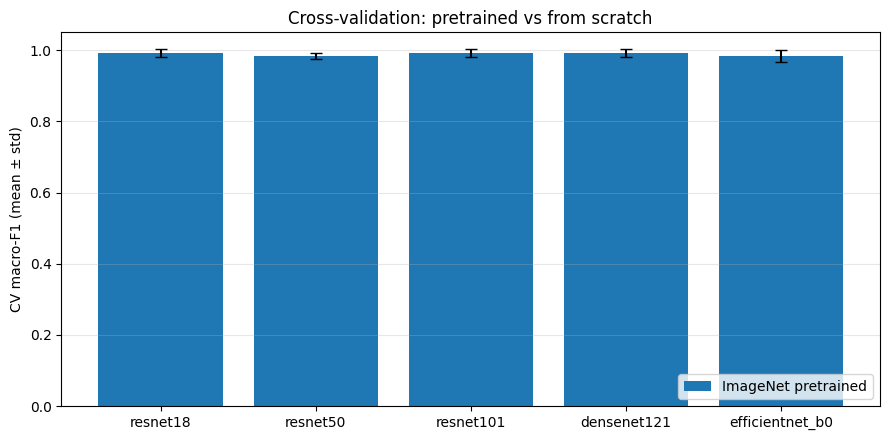

In [9]:
# Bar chart: CV macro-F1 for every model, pretrained vs from scratch
x = np.arange(len(MODEL_NAMES))
width = 0.8 / len(PRETRAINED_MODES)
fig, ax = plt.subplots(figsize=(max(7, 1.8 * len(MODEL_NAMES)), 4.5))
for i, pretrained in enumerate(PRETRAINED_MODES):
    sub = (model_summary[model_summary["pretrained"] == pretrained]
           .set_index("model").reindex(MODEL_NAMES))
    ax.bar(x + (i - (len(PRETRAINED_MODES) - 1) / 2) * width, sub["mean_macro_f1"], width,
           yerr=sub["std_macro_f1"], capsize=4,
           label="ImageNet pretrained" if pretrained else "From scratch")
ax.set_xticks(x, MODEL_NAMES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("CV macro-F1 (mean ± std)")
ax.set_title("Cross-validation: pretrained vs from scratch")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "cv_pretrained_vs_scratch.png"), dpi=150)
plt.show()

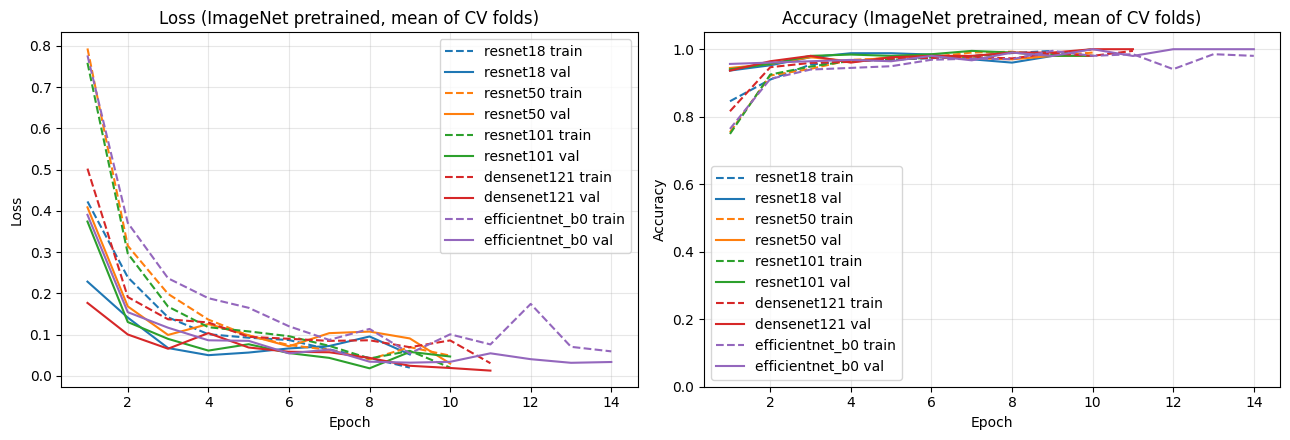

In [10]:
# Loss and accuracy curves per epoch (mean over CV folds) for every model and initialisation
def load_histories(model_name, pretrained):
    frames = []
    for fold in range(1, N_FOLDS + 1):
        path = os.path.join(OUTPUT_DIR, f"{model_name}_{init_name(pretrained)}_fold_{fold}_history.csv")
        if os.path.isfile(path):
            frames.append(pd.read_csv(path))
    if not frames:
        return None
    # folds stop at different epochs (early stopping), so average over the folds that reached each epoch
    return pd.concat(frames).groupby("epoch").mean(numeric_only=True)

fig, axes = plt.subplots(len(PRETRAINED_MODES), 2, figsize=(13, 4.5 * len(PRETRAINED_MODES)), squeeze=False)
for row, pretrained in enumerate(PRETRAINED_MODES):
    ax_loss, ax_acc = axes[row]
    for name in MODEL_NAMES:
        h = load_histories(name, pretrained)
        if h is None or "val_acc" not in h:
            print(f"No accuracy history for {name} ({init_name(pretrained)}); re-run the cross-validation cell.")
            continue
        line, = ax_loss.plot(h.index, h["train_loss"], linestyle="--", label=f"{name} train")
        ax_loss.plot(h.index, h["val_loss"], color=line.get_color(), label=f"{name} val")
        line, = ax_acc.plot(h.index, h["train_acc"], linestyle="--", label=f"{name} train")
        ax_acc.plot(h.index, h["val_acc"], color=line.get_color(), label=f"{name} val")
    title = "ImageNet pretrained" if pretrained else "From scratch"
    ax_loss.set_title(f"Loss ({title}, mean of CV folds)")
    ax_acc.set_title(f"Accuracy ({title}, mean of CV folds)")
    ax_loss.set_ylabel("Loss")
    ax_acc.set_ylabel("Accuracy")
    ax_acc.set_ylim(0, 1.05)
    for ax in (ax_loss, ax_acc):
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "loss_accuracy_curves.png"), dpi=150)
plt.show()

## 9. Train the selected models and evaluate on the held-out test set

For each initialisation (pretrained and from scratch), the selected model is retrained on all training images for the median best epoch from cross-validation, then evaluated once on the test set.


FINAL MODEL (pretrained): densenet121 | 3 epochs on all 253 training images | lr=0.0001
Class weights: {'FAF': np.float64(0.969), 'IR': np.float64(1.004), 'OTHER': np.float64(1.028)}
Final densenet121 (pretrained) epoch 01/3 | loss=0.4373
Final densenet121 (pretrained) epoch 02/3 | loss=0.1216
Final densenet121 (pretrained) epoch 03/3 | loss=0.0597

===== HELD-OUT TEST RESULTS (pretrained) =====
Selected model: densenet121
Accuracy: 1.0000
Macro F1: 1.0000
              precision    recall  f1-score   support

         FAF      1.000     1.000     1.000        22
          IR      1.000     1.000     1.000        13
       OTHER      1.000     1.000     1.000        20

    accuracy                          1.000        55
   macro avg      1.000     1.000     1.000        55
weighted avg      1.000     1.000     1.000        55

Confusion matrix (rows=true, columns=predicted):
 [[22  0  0]
 [ 0 13  0]
 [ 0  0 20]]


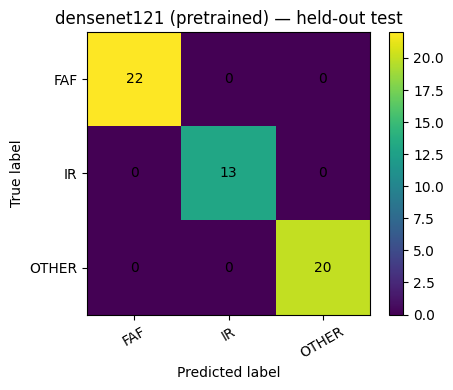


===== PRETRAINED vs FROM SCRATCH: HELD-OUT TEST =====


,initialisation,selected_model,cv_macro_f1,test_accuracy,test_macro_f1,test_recall_FAF,test_recall_IR,test_recall_OTHER
0,ImageNet,densenet121,0.992,1.0,1.0,1.0,1.0,1.0


Saved final models and metrics to: results_faf_ir_model_comparison


In [11]:
test_results = {}
test_loader = make_loader(test_df, eval_transform, train=False)

for pretrained in PRETRAINED_MODES:
    name, final_epochs, cv_f1 = SELECTED[pretrained]
    tag = init_name(pretrained)
    _, lr, _ = train_settings(pretrained)

    print("\n" + "=" * 72)
    print(f"FINAL MODEL ({tag}): {name} | {final_epochs} epochs on all "
          f"{len(train_df)} training images | lr={lr}")
    print("=" * 72)

    set_seed(SEED)
    final_train_loader = make_loader(train_df, train_transform, train=True)
    final_criterion = make_loss(train_df)
    final_model = build_model(model_name=name, pretrained=pretrained).to(DEVICE)
    optimizer = torch.optim.AdamW(final_model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)

    for epoch in range(1, final_epochs + 1):
        train_loss, _, _ = run_epoch(final_model, final_train_loader, final_criterion, optimizer)
        print(f"Final {name} ({tag}) epoch {epoch:02d}/{final_epochs} | loss={train_loss:.4f}")

    _, y_test, pred_test = run_epoch(final_model, test_loader, nn.CrossEntropyLoss())
    scores = score_predictions(y_test, pred_test)

    print(f"\n===== HELD-OUT TEST RESULTS ({tag}) =====")
    print("Selected model:", name)
    print(f"Accuracy: {scores['accuracy']:.4f}")
    print(f"Macro F1: {scores['macro_f1']:.4f}")
    print(scores["report"])
    print("Confusion matrix (rows=true, columns=predicted):\n", scores["confusion_matrix"])
    plot_confusion_matrix(scores["confusion_matrix"], f"{name} ({tag}) — held-out test")

    test_results[tag] = {
        "selected_model": name,
        "pretrained_initialisation": pretrained,
        "final_epochs": final_epochs,
        "cv_macro_f1": cv_f1,
        "accuracy": float(scores["accuracy"]),
        "macro_f1": float(scores["macro_f1"]),
        "classification_report": classification_report(
            y_test, pred_test, labels=list(range(len(CLASSES))),
            target_names=CLASSES, output_dict=True, zero_division=0
        ),
        "confusion_matrix": scores["confusion_matrix"].tolist(),
    }
    torch.save({
        "model_name": name,
        "state_dict": final_model.state_dict(),
        "classes": CLASSES,
        "image_size": IMAGE_SIZE,
        "pretrained_initialisation": pretrained,
        "circle_mask": USE_CIRCLE_MASK,
        "circle_scale": CIRCLE_SCALE,
    }, os.path.join(OUTPUT_DIR, f"final_model_{tag}.pt"))
    del final_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Side-by-side summary: pretrained vs from scratch
final_table = pd.DataFrame([
    {"initialisation": "ImageNet" if r["pretrained_initialisation"] else "Scratch",
     "selected_model": r["selected_model"],
     "cv_macro_f1": r["cv_macro_f1"],
     "test_accuracy": r["accuracy"],
     "test_macro_f1": r["macro_f1"],
     **{f"test_recall_{c}": r["classification_report"][c]["recall"] for c in CLASSES}}
    for r in test_results.values()
])
print("\n===== PRETRAINED vs FROM SCRATCH: HELD-OUT TEST =====")
display(final_table.round(3))
final_table.to_csv(os.path.join(OUTPUT_DIR, "test_pretrained_vs_scratch.csv"), index=False)

with open(os.path.join(OUTPUT_DIR, "test_metrics.json"), "w") as f:
    json.dump({
        "classes": CLASSES,
        "test_results": test_results,
        "model_comparison": model_summary.to_dict(orient="records"),
    }, f, indent=2, default=float)
print("Saved final models and metrics to:", OUTPUT_DIR)

## 10. Predict the modality of a new image

In [12]:
# Use final_model_pretrained.pt (default) or final_model_scratch.pt
def predict_modality(image_path, checkpoint_path=os.path.join(OUTPUT_DIR, "final_model_pretrained.pt")):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model = build_model(
        model_name=checkpoint["model_name"],
        pretrained=False,
        n_classes=len(checkpoint["classes"])
    )
    model.load_state_dict(checkpoint["state_dict"])
    model.to(DEVICE).eval()

    _, inference_transform = make_transforms(checkpoint["image_size"],
                                         checkpoint.get("circle_mask", False), checkpoint.get("circle_scale", 1.0))
    with Image.open(image_path) as im:
        image = im.convert("RGB")
    x = inference_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        probabilities = torch.softmax(model(x), dim=1)[0].cpu().numpy()

    ranking = sorted(
        zip(checkpoint["classes"], probabilities.tolist()),
        key=lambda item: item[1], reverse=True
    )
    return {
        "model": checkpoint["model_name"],
        "predicted_label": ranking[0][0],
        "confidence": round(ranking[0][1], 4),
        "probabilities": {label: round(prob, 4) for label, prob in ranking}
    }

# # Example:
# prediction = predict_modality("/home/tdhar/image_faf_ir/bad/0091-0_0.png")
# print(prediction)

## 11. Display misclassified held-out test images

The `bad/` folder has no ground-truth labels, so misclassification cannot be measured there. This cell uses the labeled held-out test set, compares the true labels with model predictions, saves the mistakes, and displays them.

In [13]:
def show_misclassified_images(
    labeled_df,
    checkpoint_path=os.path.join(OUTPUT_DIR, "final_model_pretrained.pt"),
    columns=4,
):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model = build_model(
        model_name=checkpoint["model_name"],
        pretrained=False,
        n_classes=len(checkpoint["classes"]),
    ).to(DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    _, inference_transform = make_transforms(checkpoint["image_size"],
                                         checkpoint.get("circle_mask", False), checkpoint.get("circle_scale", 1.0))

    mistakes = []
    for _, row in labeled_df.reset_index(drop=True).iterrows():
        image_path = row["image_path"]
        with Image.open(image_path) as image:
            x = inference_transform(image).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            probabilities = torch.softmax(model(x), dim=1)[0].cpu().numpy()
        predicted_label = checkpoint["classes"][int(np.argmax(probabilities))]
        if predicted_label != row["label"]:
            mistakes.append({
                "image_path": image_path,
                "true_label": row["label"],
                "predicted_label": predicted_label,
                "confidence": float(probabilities.max()),
            })

    mistakes_df = pd.DataFrame(mistakes)
    output_path = os.path.join(OUTPUT_DIR, "misclassified_test_images.csv")
    mistakes_df.to_csv(output_path, index=False)
    print(f"Found {len(mistakes_df)} misclassified images.")
    print(f"Saved details to: {output_path}")

    if mistakes_df.empty:
        print("No misclassified images to display.")
        return mistakes_df

    rows = int(np.ceil(len(mistakes_df) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4 * rows), squeeze=False)
    for ax, (_, mistake) in zip(axes.flat, mistakes_df.iterrows()):
        with Image.open(mistake["image_path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(
            f"True: {mistake['true_label']} | Pred: {mistake['predicted_label']}\n"
            f"Confidence: {mistake['confidence']:.1%}"
        )
        ax.axis("off")
    for ax in axes.flat[len(mistakes_df):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()
    return mistakes_df

misclassified_test = show_misclassified_images(test_df)

Found 0 misclassified images.
Saved details to: results_faf_ir_model_comparison/misclassified_test_images.csv
No misclassified images to display.


## 12. Grad-CAM for misclassified images

This visualizes the regions that most influenced the ResNet-18 prediction. The heatmap is drawn on the image **as the model sees it** (resized, padded and circle-masked), so you can check that the heat is now on the retina (optic disc, fovea, vessels) and not on the corners.

In [14]:
# import os
# from pathlib import Path
# import torch
# import matplotlib.pyplot as plt
# from PIL import Image, ImageOps

def run_gradcam(
    df,
    checkpoint_path=os.path.join(OUTPUT_DIR, "final_model_pretrained.pt"),
    show=False,
):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model_name = checkpoint["model_name"]
    model = build_model(model_name, pretrained=False, n_classes=len(CLASSES)).to(DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()

    activations, gradients = [], []

    def forward_hook(_, __, output):
        activations.append(output)
        output.register_hook(lambda grad: gradients.append(grad))

    if model_name.startswith("resnet"):
        block = model.layer4[-1]
        # Bottleneck blocks (ResNet-50/101) end in conv3; BasicBlock (ResNet-18) ends in conv2
        target_layer = block.conv3 if hasattr(block, "conv3") else block.conv2
    elif model_name.startswith("densenet"):
        target_layer = model.features.denseblock4
    else:  # efficientnet
        target_layer = model.features[-1]
    forward_handle = target_layer.register_forward_hook(forward_hook)

    _, inference_transform = make_transforms(checkpoint["image_size"],
                                             checkpoint.get("circle_mask", False), checkpoint.get("circle_scale", 1.0))
    model_view = preprocess(checkpoint["image_size"], checkpoint.get("circle_mask", False),
                            checkpoint.get("circle_scale", 1.0))
    output_dir = Path(OUTPUT_DIR) / f"gradcam_{model_name}_test"
    output_dir.mkdir(exist_ok=True)

    try:
        for _, row in df.iterrows():
            with Image.open(row["image_path"]) as image:
                original = ImageOps.exif_transpose(image).convert("RGB")
                x = inference_transform(original).unsqueeze(0).to(DEVICE)
                display_image = model_view(original)
            activations.clear()
            gradients.clear()
            model.zero_grad(set_to_none=True)

            logits = model(x)
            probs = torch.softmax(logits, dim=1)[0]
            predicted_index = int(probs.argmax().item())
            confidence = float(probs[predicted_index].item())
            predicted_label = CLASSES[predicted_index]
            logits[0, predicted_index].backward()

            feature_maps = activations[-1][0]
            weights = gradients[-1][0].mean(dim=(1, 2))
            cam = torch.relu((weights[:, None, None] * feature_maps).sum(dim=0))
            cam = torch.nn.functional.interpolate(
                cam[None, None], size=display_image.size[::-1], mode="bilinear", align_corners=False
            )[0, 0].detach().cpu().numpy()
            cam -= cam.min()
            if cam.max() > 0:
                cam /= cam.max()

            fig, axes = plt.subplots(1, 3, figsize=(13, 4))
            axes[0].imshow(display_image)
            axes[0].set_title(f"Input\nTrue: {row['true_label']}")
            axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
            axes[1].set_title(f"Grad-CAM\nPred: {predicted_label}")
            axes[2].imshow(display_image)
            axes[2].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
            axes[2].set_title(f"Overlay\nConfidence: {confidence:.1%}")
            for ax in axes:
                ax.axis("off")
            fig.tight_layout()
            output_path = output_dir / f"{Path(row['image_path']).stem}_gradcam.png"
            fig.savefig(output_path, dpi=180, bbox_inches="tight")
            if show:
                plt.show()
            plt.close(fig)
            print(f"Saved: {output_path}")
    finally:
        forward_handle.remove()

In [15]:
# from PIL import ImageFilter

# def compare(path, ckpt=os.path.join(OUTPUT_DIR, "final_model_pretrained.pt")):
#     img = Image.open(path).convert("RGB")
#     w, h = img.size; s = int(min(w, h) * 0.70)
#     square = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2))   # no round outline
#     smooth = img.filter(ImageFilter.MedianFilter(5))                               # grain removed
#     for name, im in [("original", img), ("square crop (no shape)", square), ("grain removed", smooth)]:
#         im.save("/tmp/_cmp.png")
#         r = predict_modality("/home/tdhar/image_faf_ir/images_test/FAF/0019_AF_B-0_0.png", ckpt)
#         print(f"{name:24s} -> {r['predicted_label']} {r['probabilities']}")



In [16]:
# def zoom_sweep(path, ckpt=os.path.join(OUTPUT_DIR, "final_model_pretrained.pt")):
#     print("checkpoint saved:", time.ctime(os.path.getmtime(ckpt)),
#           "| circle mask:", torch.load(ckpt, map_location="cpu").get("circle_mask", False))
#     img = Image.open(path).convert("RGB")
#     w, h = img.size
#     for zoom in [1.0, 1.1, 1.2, 1.3, 1.4, 1.5]:
#         s = int(min(w, h) / zoom)
#         im = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2))
#         im.save("/tmp/_cmp.png")
#         r = predict_modality("/home/tdhar/image_faf_ir/images_test/FAF/0019_AF_B-0_0.png", ckpt)
#         print(f"zoom {zoom:.1f}x -> {r['predicted_label']:5s} {r['probabilities']}")


In [17]:
def gradcam_layer(model, model_name):
    # last convolutional block of each supported network
    if model_name.startswith("resnet"):
        return model.layer4[-1]
    if model_name.startswith("densenet"):
        return model.features.norm5
    if model_name.startswith("efficientnet"):
        return model.features[-1]
    raise ValueError(f"No Grad-CAM layer defined for {model_name}")

def predict_modality_tta(image_path, checkpoint_path=os.path.join(OUTPUT_DIR, "final_model_pretrained.pt"),
                         zooms=(1.0, 1.1), flip=True, show_gradcam=True):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model = build_model(checkpoint["model_name"], pretrained=False, n_classes=len(checkpoint["classes"]))
    model.load_state_dict(checkpoint["state_dict"])
    model.to(DEVICE).eval()
    classes = checkpoint["classes"]
    _, tf = make_transforms(checkpoint["image_size"],
                            checkpoint.get("circle_mask", False), checkpoint.get("circle_scale", 1.0))

    with Image.open(image_path) as im:
        img = im.convert("RGB")
    w, h = img.size
    views, names = [], []
    for z in zooms:                                   # centre zoom, keeps the image's own proportions
        cw, ch = int(w / z), int(h / z)
        v = img.crop(((w - cw) // 2, (h - ch) // 2, (w + cw) // 2, (h + ch) // 2))
        views.append(v); names.append(f"zoom {z:.1f}x")
        if flip:
            views.append(ImageOps.mirror(v)); names.append(f"zoom {z:.1f}x mirrored")
    x = torch.stack([tf(v) for v in views]).to(DEVICE)

    # one forward pass for all views; keep the last conv block's output for Grad-CAM
    store = {}
    hook = gradcam_layer(model, checkpoint["model_name"]).register_forward_hook(
        lambda m, i, o: store.__setitem__("act", o))
    with torch.enable_grad():
        logits = model(x)
        probs_each = torch.softmax(logits, dim=1)
        probs = probs_each.mean(0)                                  # average over all views
        k = int(probs.argmax())                                     # final (averaged) class
        grads = torch.autograd.grad(logits[:, k].sum(), store["act"])[0]
    hook.remove()

    ranking = sorted(zip(classes, probs.tolist()), key=lambda t: t[1], reverse=True)
    result = {"model": checkpoint["model_name"], "predicted_label": ranking[0][0],
              "confidence": round(ranking[0][1], 4),
              "probabilities": {c: round(p, 4) for c, p in ranking},
              "views": len(views),
              "per_view": {n: {c: round(float(p), 4) for c, p in zip(classes, pv)}
                           for n, pv in zip(names, probs_each.detach().cpu().numpy())}}

    if show_gradcam:
        act = store["act"].detach()
        cams = torch.relu((grads.mean((2, 3), keepdim=True) * act).sum(1, keepdim=True))
        cams = torch.nn.functional.interpolate(cams, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cams = (cams / (cams.amax((1, 2), keepdim=True) + 1e-8)).cpu().numpy()
        mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

        n = len(views)
        fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6.6), squeeze=False)
        for j in range(n):
            shown = (x[j].cpu().permute(1, 2, 0).numpy() * std + mean).clip(0, 1)   # exactly what the model saw
            pv = probs_each[j].detach().cpu().numpy()
            axes[0, j].imshow(shown)
            axes[0, j].set_title(f"{names[j]}\n{classes[int(pv.argmax())]} {pv.max():.0%}", fontsize=9)
            axes[1, j].imshow(shown)
            axes[1, j].imshow(cams[j], cmap="jet", alpha=0.45, vmin=0, vmax=1)
            axes[1, j].set_title(f"evidence for {classes[k]}\n({classes[k]} {pv[k]:.0%})", fontsize=9)
            for ax in axes[:, j]:
                ax.axis("off")
        fig.suptitle(f"{os.path.basename(image_path)}  |  average over {n} views: "
                     f"{result['predicted_label']} {result['confidence']:.1%}", fontsize=11)
        fig.tight_layout()
        out = os.path.join(OUTPUT_DIR, f"{Path(image_path).stem}_tta_gradcam.png")
        fig.savefig(out, dpi=150, bbox_inches="tight")
        plt.show()
        print("Saved:", out)
    return result



In [18]:
run_gradcam(misclassified_test,
            checkpoint_path=os.path.join(OUTPUT_DIR, "final_model_pretrained.pt"),
            show=True)

In [19]:
# import numpy as np, torch
# from PIL import Image
# from torchvision import transforms

# path = "/home/tdhar/image_faf_ir/images_test/FAF/0019_AF_B-0_0.png"
# norm = transforms.Compose([transforms.ToTensor(),
#         transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
# classes = sorted(CLASS_TO_IDX, key=CLASS_TO_IDX.get)

# # Load the saved model (use final_model_scratch.pt for the scratch model)
# ckpt = torch.load(os.path.join(OUTPUT_DIR, "final_model_pretrained.pt"), map_location=DEVICE)
# model = build_model(ckpt["model_name"], pretrained=False, n_classes=len(CLASSES)).to(DEVICE)
# model.load_state_dict(ckpt["state_dict"])

# a = np.array(preprocess(ckpt["image_size"], ckpt.get("circle_mask", False), ckpt.get("circle_scale", 1.0))(Image.open(path).convert("RGB")))
# b = a.copy()
# h = a.shape[0]
# fill = a[a.sum(2) > 0].mean(0)            
# bottom = b[int(h*0.72):]                   
# bottom[bottom.sum(2) > 0] = fill           

# model.eval()
# for name, arr in [("original", a), ("bottom covered", b)]:
#     with torch.no_grad():
#         p = torch.softmax(model(norm(Image.fromarray(arr)).unsqueeze(0).to(DEVICE)), 1)[0].cpu().numpy()
#     print(f"{name:15s}", {c: round(float(x), 3) for c, x in zip(classes, p)})

In [20]:
# import numpy as np
# from PIL import Image

# def bright_spot_ratio(path, k=3.0):
#     g = np.array(preprocess()(Image.open(path).convert("RGB")).convert("L")).astype(float)
#     inside = g[g > 0]                          
#     thr = inside.mean() + k * inside.std()     
#     return (inside > thr).mean() * 100         

# train_df["bright_%"] = train_df["image_path"].apply(bright_spot_ratio)
# train_df["has_spots"] = train_df["bright_%"] > 0.5
# print(train_df.groupby("label")["has_spots"].agg(["sum", "mean"]).round(2))

# print("this image:", round(bright_spot_ratio(path), 2), "%")

## Notes before reporting results

- Every image is circle-masked (`USE_CIRCLE_MASK`) so the round vs square outline cannot be used as a shortcut. Check the Grad-CAM: the heat should be on the retina, not the corners.
- The notebook trains on image pixels only. Metadata columns are not model features.
- The CSV needs `image_path` and `label`. A patient/subject ID, if present, is used only for grouped cross-validation.
- Report macro-F1, per-class precision/recall/F1, and the confusion matrix—not accuracy alone.
- Check whether `OTHER` is a coherent class or a mixture of different modalities.
- If the data contain multiple images per patient, patient-level separation is important. Without an ID column, the notebook cannot guarantee patient-level separation.
- Pretrained vs scratch: expect clearly lower and less stable scores from scratch with ~240 images. This comparison shows the benefit of transfer learning; report the pretrained model as the main result.
- The model comparison is compute-intensive: three models × two initialisations × cross-validation folds (30 training runs with the defaults), and scratch runs take longer. For a first run, you can reduce `MODEL_NAMES` to three models or reduce `N_FOLDS` to 3 if the class counts permit.
- Pretrained weights may be downloaded by torchvision the first time. Results are not guaranteed; use the held-out test results only after cross-validation model selection.

In [21]:
# Predict images from a single path, a list of paths, or a whole folder.
# Uses predict_modality (cell above) with the final pretrained model.
IMAGE_PATHS = "/home/tdhar/image_faf_ir/bad"   # an image file, a folder, or a list of files
CHECKPOINT = os.path.join(OUTPUT_DIR, "final_model_pretrained.pt")   # or final_model_scratch.pt

EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")
paths = [IMAGE_PATHS] if isinstance(IMAGE_PATHS, (str, os.PathLike)) else list(IMAGE_PATHS)
files = []
for p in paths:
    p = str(p)
    if os.path.isdir(p):
        files += sorted(os.path.join(p, f) for f in os.listdir(p) if f.lower().endswith(EXTS))
    elif os.path.isfile(p):
        files.append(p)
    else:
        print(f"Not found: {p}")

rows = []
for f in files:
    r = predict_modality(f, checkpoint_path=CHECKPOINT)
    rows.append({"image": os.path.basename(f), "prediction": r["predicted_label"],
                 "confidence": r["confidence"], **{f"p_{c}": r["probabilities"].get(c) for c in CLASSES}})

predictions_df = pd.DataFrame(rows)
display(predictions_df)
if len(predictions_df):
    print(predictions_df["prediction"].value_counts().to_string())
    predictions_df.to_csv(os.path.join(OUTPUT_DIR, "new_image_predictions.csv"), index=False)

,image,prediction,confidence,p_FAF,p_IR,p_OTHER
0,0009_SLO_IR-0_0.png,IR,0.9978,0.0008,0.9978,0.0013
1,0013_SLO_IR-0_0.png,IR,0.9927,0.0031,0.9927,0.0041
2,0017_SLO_IR-0_0.png,IR,0.9993,0.0002,0.9993,0.0004
3,0028_SLO_IR-0_0.png,IR,0.9986,0.0006,0.9986,0.0008
4,0039_SLO_IR-0_0.png,IR,0.9992,0.0001,0.9992,0.0007
5,0042_SLO_IR-0_0.png,IR,0.9966,0.0008,0.9966,0.0026
6,0053_SLO_IR-0_0.png,IR,0.9978,0.0003,0.9978,0.0019
7,0059_SLO_IR-0_0.png,IR,0.9993,0.0001,0.9993,0.0005
8,0063_AF_B-0_0.png,FAF,0.8758,0.8758,0.0023,0.1220
9,0065_SLO_IR-0_0.png,IR,0.9972,0.0002,0.9972,0.0027


prediction
IR     12
FAF     2
